# SolarSelect — Consolidated EDA Findings and Dataset Selection

**Directory:** `notebooks/eda2.0/`  
**Notebook:** `consolidated_eda_findings_and_dataset_selection.ipynb`  
**Phase:** Phase 2 — Exploratory Data Analysis (Task 6 — Formal Phase Closure)  
**Objective:** Consolidate empirical and physical findings from Tasks 1–5, formalize the evidence-based dataset selection strategy for SolarSelect, establish technical feature and target recommendations, document the comprehensive risk register, and deliver a structured handover for Phase 3 (Target Definition and Data Preparation).  
**Working Rule:** Strictly consolidation, synthesis, and technical handover. Zero ML model training. Zero raw data modification. Zero Phase 3 pipeline execution.

---

## 1. Project Context & Dual-Layer Architecture

SolarSelect is conceived as an end-to-end, production-grade MLOps system delivering:
$$\text{Climate-Conditioned Specific Yield Forecasting} + \text{Constraint-Aware Panel Recommendation} + \text{Uncertainty Estimation}$$

The application operates across two tightly coupled architectural layers:
1. **Layer A (Predictive Engine):** Machine learning-based forecasting of solar energy performance under ambient environmental and meteorological conditions. Outputs specific energy yield ($Y_f = \text{kWh}/\text{kW}_p$) alongside calibrated uncertainty intervals to quantify climatological and weather variability.
2. **Layer B (Prescriptive Recommendation Engine):** Constraint-aware solar panel optimization system. Evaluates commercial panel datasheets (CEC-verified parameters, temperature coefficients, nominal efficiency, degradation curves), physical roof geometry, local shading, capital expenditure budgets, and regulatory net-metering thresholds to prescribe optimal hardware configurations for user installations.

### Role of Exploratory Data Analysis (Tasks 1–6):
To establish an unshakeable empirical foundation for Layer A and Layer B, Phase 2 conducted five deep investigative tasks across eight raw CSV datasets:
- **Task 1 (Inspection & Schema):** Verification of row counts, data types, physical schemas, and temporal boundaries.
- **Task 2 (Data Quality & Completeness):** Multi-tiered missingness audits, timestamp alignment, inverter dropout rates, and sensor gap characterization.
- **Task 3 (Distributions & Physics):** 8-number statistical summaries, physical sanity checks, DC/AC operating ratios ($10.0\times$ sensor scaling discovery), and nighttime pulse audits.
- **Task 4 (Temporal, Seasonal & Site-Wise):** Value-encoding diagnostics, valid site-day definition, fixed 37-site cohort construction, 12-month complete annual cycle analysis, corrected capacity-normalized yield calculations, and site-level reliability.
- **Task 5 (Features, Relationships & Targets):** Autoregressive lag persistence, temperature collinearity diagnostics, technical target feasibility audits, cross-dataset incompatibility proof, and risk register formulation.

This notebook synthesizes all verified findings into an authoritative dataset strategy and Phase 3 technical handover.


In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import Image, display

# Verify repository root and raw data directory
repo_root = os.path.abspath(os.path.join(os.getcwd(), "../.."))
data_dir = os.path.join(repo_root, "data", "raw")
archive_dir = os.path.join(data_dir, "archive")
unisolar_dir = os.path.join(data_dir, "unisolar")

print(f"Repository Root: {repo_root}")
print(f"Archive Data Directory: {archive_dir} (Exists: {os.path.exists(archive_dir)})")
print(f"UNISOLAR Data Directory: {unisolar_dir} (Exists: {os.path.exists(unisolar_dir)})")

# Set display options for clean presentation
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)


Repository Root: /Users/apple/Documents/5th sem el/MLOps_EL/SolarSelect
Archive Data Directory: /Users/apple/Documents/5th sem el/MLOps_EL/SolarSelect/data/raw/archive (Exists: True)
UNISOLAR Data Directory: /Users/apple/Documents/5th sem el/MLOps_EL/SolarSelect/data/raw/unisolar (Exists: True)


---
## 2. Consolidated Dataset Inventory

SolarSelect evaluated eight primary datasets partitioned into two distinct sources:
1. **Original Kaggle Solar Datasets (`data/raw/archive/`):** Two large-scale utility solar power plants located in semi-arid India, monitored over a contiguous 34-day operational span (May–June 2020) at 15-minute resolution with direct weather pyranometer sensors.
2. **UNISOLAR Supplementary Dataset (`data/raw/unisolar/`):** A distributed network of 42 commercial rooftop solar PV installations across five university campuses in Victoria, Australia, monitored over an approximately 28-month operational span (January 2020 – April 2022) at 15-minute resolution with regional BoM weather stations.


In [2]:
# Construct Authoritative Dataset Inventory
inventory_data = [
    {
        "Dataset Identifier": "Kaggle Plant 1 Generation",
        "File Name": "Plant_1_Generation_Data.csv",
        "Directory": "data/raw/archive/",
        "Row Count": 68778,
        "Col Count": 7,
        "Temporal Span": "2020-05-15 to 2020-06-17 (34 days)",
        "Resolution": "15-minute",
        "Key Entities": "22 Inverters (Plant 1)",
        "Missingness": "0.0% (0 nulls)",
        "Capacity Metadata": "Unrecorded (0 kWp)"
    },
    {
        "Dataset Identifier": "Kaggle Plant 1 Weather",
        "File Name": "Plant_1_Weather_Sensor_Data.csv",
        "Directory": "data/raw/archive/",
        "Row Count": 3182,
        "Col Count": 6,
        "Temporal Span": "2020-05-15 to 2020-06-17 (34 days)",
        "Resolution": "15-minute",
        "Key Entities": "Plant 1 Sensor Array",
        "Missingness": "0.0% (0 nulls)",
        "Capacity Metadata": "N/A (Meteorological)"
    },
    {
        "Dataset Identifier": "Kaggle Plant 2 Generation",
        "File Name": "Plant_2_Generation_Data.csv",
        "Directory": "data/raw/archive/",
        "Row Count": 67698,
        "Col Count": 7,
        "Temporal Span": "2020-05-15 to 2020-06-17 (34 days)",
        "Resolution": "15-minute",
        "Key Entities": "22 Inverters (Plant 2)",
        "Missingness": "0.0% (0 nulls)",
        "Capacity Metadata": "Unrecorded (0 kWp)"
    },
    {
        "Dataset Identifier": "Kaggle Plant 2 Weather",
        "File Name": "Plant_2_Weather_Sensor_Data.csv",
        "Directory": "data/raw/archive/",
        "Row Count": 3259,
        "Col Count": 6,
        "Temporal Span": "2020-05-15 to 2020-06-17 (34 days)",
        "Resolution": "15-minute",
        "Key Entities": "Plant 2 Sensor Array",
        "Missingness": "0.0% (0 nulls)",
        "Capacity Metadata": "N/A (Meteorological)"
    },
    {
        "Dataset Identifier": "UNISOLAR Site Details",
        "File Name": "Solar_Site_Details.csv",
        "Directory": "data/raw/unisolar/",
        "Row Count": 42,
        "Col Count": 10,
        "Temporal Span": "Static Installation Metadata",
        "Resolution": "Site-level",
        "Key Entities": "42 Sites across 5 Campuses",
        "Missingness": "40.48% kWp (17/42 missing)",
        "Capacity Metadata": "Documented for 25 sites"
    },
    {
        "Dataset Identifier": "UNISOLAR Generation",
        "File Name": "Solar_Energy_Generation.csv",
        "Directory": "data/raw/unisolar/",
        "Row Count": 2731946,
        "Col Count": 4,
        "Temporal Span": "2020-01-01 to 2022-04-30 (~28 mos)",
        "Resolution": "15-minute",
        "Key Entities": "42 Rooftop Sites",
        "Missingness": "56.23% (1,536,301 nulls)",
        "Capacity Metadata": "Linked via SiteKey"
    },
    {
        "Dataset Identifier": "UNISOLAR Weather",
        "File Name": "Weather_Data_reordered_all.csv",
        "Directory": "data/raw/unisolar/",
        "Row Count": 371769,
        "Col Count": 8,
        "Temporal Span": "2020-01-01 to 2022-04-30 (~28 mos)",
        "Resolution": "15-minute",
        "Key Entities": "5 Regional Campus Loggers",
        "Missingness": "28.81% Temp, 43.81% Wind",
        "Capacity Metadata": "N/A (Meteorological)"
    },
    {
        "Dataset Identifier": "UNISOLAR Monthly Summary",
        "File Name": "Monthly_Summary_Solar.csv",
        "Directory": "data/raw/unisolar/",
        "Row Count": 1176,
        "Col Count": 5,
        "Temporal Span": "2020-01 to 2022-04 (28 months)",
        "Resolution": "Monthly",
        "Key Entities": "42 Sites x 28 Months",
        "Missingness": "17.01% (200 null entries)",
        "Capacity Metadata": "N/A (Macro Aggregation)"
    }
]

df_inventory = pd.DataFrame(inventory_data)
print("=== SOLARSELECT CONSOLIDATED DATASET INVENTORY ===")
display(df_inventory[["Dataset Identifier", "File Name", "Row Count", "Temporal Span", "Key Entities", "Missingness", "Capacity Metadata"]])


=== SOLARSELECT CONSOLIDATED DATASET INVENTORY ===


,Dataset Identifier,File Name,Row Count,Temporal Span,Key Entities,Missingness,Capacity Metadata
0,Kaggle Plant 1 Generation,Plant_1_Generation_Data.csv,68778,2020-05-15 to 2020-06-17 (34 days),22 Inverters (Plant 1),0.0% (0 nulls),Unrecorded (0 kWp)
1,Kaggle Plant 1 Weather,Plant_1_Weather_Sensor_Data.csv,3182,2020-05-15 to 2020-06-17 (34 days),Plant 1 Sensor Array,0.0% (0 nulls),N/A (Meteorological)
2,Kaggle Plant 2 Generation,Plant_2_Generation_Data.csv,67698,2020-05-15 to 2020-06-17 (34 days),22 Inverters (Plant 2),0.0% (0 nulls),Unrecorded (0 kWp)
3,Kaggle Plant 2 Weather,Plant_2_Weather_Sensor_Data.csv,3259,2020-05-15 to 2020-06-17 (34 days),Plant 2 Sensor Array,0.0% (0 nulls),N/A (Meteorological)
4,UNISOLAR Site Details,Solar_Site_Details.csv,42,Static Installation Metadata,42 Sites across 5 Campuses,40.48% kWp (17/42 missing),Documented for 25 sites
5,UNISOLAR Generation,Solar_Energy_Generation.csv,2731946,2020-01-01 to 2022-04-30 (~28 mos),42 Rooftop Sites,"56.23% (1,536,301 nulls)",Linked via SiteKey
6,UNISOLAR Weather,Weather_Data_reordered_all.csv,371769,2020-01-01 to 2022-04-30 (~28 mos),5 Regional Campus Loggers,"28.81% Temp, 43.81% Wind",N/A (Meteorological)
7,UNISOLAR Monthly Summary,Monthly_Summary_Solar.csv,1176,2020-01 to 2022-04 (28 months),42 Sites x 28 Months,17.01% (200 null entries),N/A (Macro Aggregation)


---
## 3. Consolidated Findings from Tasks 1–5

### A. Dataset Structure & Key Entity Architecture
1. **Kaggle Solar Power Plants (P1 & P2):**
   - Each plant contains exactly **22 distinct string inverters** (identified by 16-character alphanumeric `SOURCE_KEY` strings) feeding into central SCADA loggers.
   - Plant 1 contains $68,778$ inverter generation rows across $3,158$ unique timestamps; Plant 2 contains $67,698$ rows across $3,259$ timestamps.
   - Primary join key between generation and weather is composite: `['PLANT_ID', 'DATE_TIME']` (requiring timestamp parsing across differing string formats: `%d-%m-%Y %H:%M` for generation vs. `%Y-%m-%d %H:%M:%S` for weather).
2. **UNISOLAR Distributed Rooftop PV:**
   - Encompasses **42 distinct commercial rooftop solar sites** distributed across five campuses in Victoria, Australia (Campus 1: 27 sites; Campus 2: 4 sites; Campus 3: 7 sites; Campus 4: 2 sites; Campus 5: 2 sites).
   - `Solar_Site_Details.csv` establishes spatial coordinates ($-37.718^\circ$ to $-34.205^\circ\text{ S}$, $142.167^\circ$ to $146.849^\circ\text{ E}$), documented DC capacity (`kWp`), module count, panel manufacturer, inverter model, and campus hierarchy.
   - Primary join key between generation and weather is composite: `['CampusKey', 'Timestamp']`. Generation joins to site metadata via `['SiteKey']`.

---

### B. Data Quality, Completeness & Alignment
1. **Missingness Topology:**
   - **Kaggle:** Zero missing values ($0.0\%$) across all columns in both plants. Plant 2 exhibits an operational inverter dropout rate of **$27.7\%$** ($904$ timestamps reporting fewer than the full 22 active inverters).
   - **UNISOLAR Generation:** Exactly **$56.23\%$** of rows ($1,536,301$ out of $2,731,946$) are stored as `NaN`. Audit proves this represents an intentional telemetry design: values below a hardware floor threshold ($0.1000\text{ kWh}$) and nighttime states are recorded as null rather than numerical zero.
   - **UNISOLAR Weather:** $371,769$ physical rows contain $264,656$ valid air temperature readings ($28.81\%$ null) and $208,879$ valid wind speed readings ($43.81\%$ null). Campus 2 lacks weather telemetry entirely; Campus 3 lacks wind telemetry.
2. **Capacity Metadata Availability:**
   - Exactly **$40.48\%$** of sites ($17$ out of $42$) completely lack installed capacity ratings (`kWp`).
   - Documented capacity exists strictly for **25 sites on Campus 1** (totaling $1,063.15\text{ kW}_p$, array sizes ranging from $7.20$ to $140.00\text{ kW}_p$, mean $42.53\text{ kW}_p$).
   - Campuses 2–5 ($15$ sites) and Campus 1 Sites 28–29 have unrecorded nameplate capacities. In accordance with strict project rules, **capacity must not be reverse-engineered from observed peak output**.
3. **Data Integrity & Inverter Anomalies:**
   - Plant 2 inverter `rrq4fwMUR8DrLLm` exhibits a midday counter reset where `DAILY_YIELD` abruptly resets from $\sim 8,000\text{ kWh}$ to $0$, and `TOTAL_YIELD` resets by several hundred megawatt-hours.
   - All $177$ UNISOLAR nighttime generation records ($23:00$ to $03:00$) were audited: $86.4\%$ belong to Site 27 (representing discrete pulse meter resolution on a large $539.8\text{ kW}_p$ system), $13.0\%$ belong to Site 26 (logger clock drift), and $1$ record belongs to Site 3 ($8.72\text{ kWh}$ buffer flush). Zero persistent nighttime power generation exists.

---

### C. Statistical & Physical Behaviour
1. **DC/AC Conversion & Systemic Sensor Scaling:**
   - Plant 1 exhibits a systemic daytime median DC/AC operating ratio of **$10.2202$** ($\sigma = 0.0482$), whereas Plant 2 exhibits a daytime median of **$1.0220$** ($\sigma = 0.0053$).
   - The ratio between plant medians is exactly **$10.000$**, identifying an uncorrected decimal sensor channel scaling discrepancy in Plant 1 (`DC_POWER` recorded in units $10\times$ higher than nominal). Raw data preserved unmodified; intermediate `DC_POWER` excluded from predictive inputs.
2. **Environmental Driving Relationships:**
   - **Kaggle:** On-site `IRRADIATION` (irradiance-related measurement) is the near-perfect physical driver of inverter AC power, correlating at **$r = 0.9846$** in Plant 1 and **$r = 0.9403$** in Plant 2. Ambient and module temperatures correlate positively with power due to solar heating co-movement, while physical thermal derating ($dP/dT < 0$) operates secondarily at peak irradiance.
   - **UNISOLAR:** Because UNISOLAR lacks an on-site solar pyranometer, ambient weather serves only as an indirect seasonal proxy: `AirTemperature` correlates at **$r = +0.1939$**, while `RelativeHumidity` correlates at **$r = -0.2284$**.
3. **Weather Feature Collinearity:**
   - Severe collinearity exists between `AirTemperature` and `ApparentTemperature` (**$r = 0.9641$**), while `RelativeHumidity` correlates negatively with `AirTemperature` (**$r = -0.7268$**). Including perceived or dew-point temperatures alongside air temperature causes severe variance inflation.

---

### D. Temporal, Seasonal, and Site-Wise Dynamics (Task 4 Corrected Reference)
1. **Valid Site-Day Methodology:**
   - To eliminate the distortion of missing 15-minute telemetry intervals, Task 4 established the **valid site-day criterion**: a site-day must contain $96$ contiguous physical rows and at least **$26$ out of $28$ ($90\%$) non-null intervals during core daytime hours ($09:00$ to $15:45$)**. Across the fleet, $20,809$ of $28,677$ site-days ($72.56\%$) meet this threshold.
2. **Fixed Cohort Construction & 12-Month Annual Cycle:**
   - To control for fleet expansion, staggered commissioning, and variable telemetry completeness, Task 4 constructed a **fixed 37-site cohort** requiring $\ge 10$ valid site-days in every single month across the common 12-month window: **May 2021 – April 2022**.
   - Exactly **$24$ sites** within this fixed cohort possess documented DC capacity ratings (`kWp`).
   - The fixed-cohort analysis window spans **12 calendar months**, capturing exactly **1 complete annual cycle** of Southern-Hemisphere seasonality. This is strictly distinguished from the broader UNISOLAR dataset, which spans approximately 28 months.
3. **Corrected Seasonal Variation & Specific-Yield Baseline:**
   - Controlled summer-to-winter generation ratios on the fixed cohort are **$2.36\times$** (cohort daily sum), **$2.55\times$** (cohort daily median), and **$2.41\times$** (median specific yield across 24 documented sites: $4.328$ vs. $1.795\text{ kWh}/\text{kW}_p/\text{day}$), with a within-site median ratio of **$2.46\times$** (IQR $[2.30, 2.58]$).
   - Replaced the older, inflated specific-yield formula with the true valid site-day energy sum divided by documented $\text{kW}_p$. The **peer cohort median specific yield across 23 Campus 1 sites (excluding anomalous Sites 19 & 24) is $2.94\text{ kWh}/\text{kW}_p/\text{day}$** (IQR $[2.86, 3.12]$, corresponding to 24-hour capacity factors of $10.8\%–13.8\%$).
4. **Weekday vs. Weekend Operational Invariance:**
   - Aggregated daily generation shows no statistically significant weekday vs. weekend difference (AR(1)-adjusted Welch $p = 0.1055$; paired within-week $t$-test across 48 weeks $p = 0.0895$). Calibrated conclusion: *No statistically significant weekday–weekend difference was detected in the analysed sample. This does not establish the absence of operational or scheduling effects.*
5. **Provisional Site Data-Quality Concerns:**
   - **Site 19:** Corrected daily specific yield of **$18.21\text{ kWh}/\text{kW}_p/\text{day}$** ($6.20\times$ peer median, 24h Capacity Factor **$75.87\%$**; peak 15-min power $492.06\%$ of documented STC). Feeder/building aggregation is a plausible hypothesis, not a confirmed fact.
   - **Site 24:** Corrected daily specific yield of **$6.08\text{ kWh}/\text{kW}_p/\text{day}$** ($2.07\times$ peer median, 24h Capacity Factor **$25.34\%$**; peak power $176.66\%$ of STC). Underreported DC capacity is a plausible hypothesis.
   - **Site 16 ($1.68\text{ kWh}/\text{kW}_p/\text{day}$) & Site 39 ($2.07\text{ kWh}/\text{kW}_p/\text{day}$):** Unusually low specific yields ($0.57\times$ and $0.70\times$ peer median); first observed generation dates (`2020-12-09` and `2020-08-21`) reported strictly as dataset entry dates, not confirmed commissioning dates.
   - Both Sites 19 and 24 are carried forward as **provisional data-quality concerns**, with a formal recommendation for Phase 3 sensitivity analysis.

---

### E. Feature Suitability, Time Dynamics & Target Feasibility (Task 5 Corrected Reference)
1. **Autoregressive Dynamics & Time Encodings:**
   - Generation exhibits extreme short-term autoregressive inertia (Lag 1 $15\text{m}$ $r > 0.92$, Lag 2 $30\text{m}$ $r > 0.85$, Lag 4 $1\text{h}$ $r > 0.73$), with PACF cutting off sharply after lag 2. Diurnal solar forcing produces strong 24-hour cyclicity at Lag 96 ($r \approx 0.60–0.74$).
   - Continuous cyclical transformations $\sin(2\pi h / 24)$ and $\cos(2\pi h / 24)$ successfully eliminate the artificial midnight boundary discontinuity.
2. **Target Technical Feasibility:**
   - **Kaggle:** Fully supports short-horizon instantaneous power forecasting (`AC_POWER` in kW) and derived energy ($E_{15\text{m}} = \text{AC} \times 0.25$). **Cannot support capacity-normalized specific yield ($Y_f$)** due to zero documented $\text{kW}_p$ ratings.
   - **UNISOLAR:** Target variable availability (`SolarGeneration` in kWh) is recorded across 42 sites, but observation quality is constrained by $56.23\%$ missingness ($1,536,301$ nulls). Absolute energy forecasting is feasible with observation filtering and coverage assessment (sites vary in temporal suitability). **Daily specific yield ($Y_f = \text{kWh}/\text{kW}_p/\text{day}$)** is technically supportable on verified valid site-days strictly for the 24 documented Campus 1 cohort sites over the 12-month fixed-cohort window.
3. **Cross-Dataset Compatibility:**
   - Pooling Kaggle and UNISOLAR into a joint tabular dataset is scientifically invalid due to semantic target mismatch (kW vs. kWh), severe covariate shift (on-site pyranometer vs. zero irradiance), capacity metadata absence, and disparate geographic climates.


In [3]:
# Summary Verification Metrics Table from Tasks 1-5
metrics_data = [
    {"Investigation / Metric": "Plant 1 DC/AC Median Ratio", "Task": "Task 3", "Verified Value": "10.2202 (sigma = 0.0482)", "Scientific Interpretation": "Systemic 10.0x decimal sensor scaling channel discrepancy"},
    {"Investigation / Metric": "Plant 2 DC/AC Median Ratio", "Task": "Task 3", "Verified Value": "1.0220 (sigma = 0.0053)", "Scientific Interpretation": "Nominal physical inverter operating ratio"},
    {"Investigation / Metric": "UNISOLAR Generation Value Encoding", "Task": "Task 4", "Verified Value": "0 exact zeros; 0 values < 0.1 kWh", "Scientific Interpretation": "Sub-threshold (<0.1 kWh) & night recorded as NaN (56.23% null)"},
    {"Investigation / Metric": "Valid Site-Day Pass Rate", "Task": "Task 4", "Verified Value": "20,809 / 28,677 site-days (72.56%)", "Scientific Interpretation": "A-priori filter: 96 rows + >= 26/28 core daytime non-null intervals"},
    {"Investigation / Metric": "Consistent Cohort Size & Span", "Task": "Task 4", "Verified Value": "37 sites (24 documented kWp), 12 mos", "Scientific Interpretation": "May 2021 - Apr 2022 (1 complete annual cycle; >= 10 valid days/mo)"},
    {"Investigation / Metric": "Peer Cohort Median Specific Yield", "Task": "Task 4/5", "Verified Value": "2.94 kWh / kWp / day (IQR [2.86, 3.12])", "Scientific Interpretation": "Corrected baseline across 23 peer sites (24h Capacity Factor 12.25%)"},
    {"Investigation / Metric": "Site 19 Corrected Specific Yield", "Task": "Task 4/5", "Verified Value": "18.21 kWh / kWp / day (CF 75.87%)", "Scientific Interpretation": "Provisional data-quality concern; feeder aggregation hypothesis"},
    {"Investigation / Metric": "Site 24 Corrected Specific Yield", "Task": "Task 4/5", "Verified Value": "6.08 kWh / kWp / day (CF 25.34%)", "Scientific Interpretation": "Provisional data-quality concern; underreported DC capacity hypothesis"},
    {"Investigation / Metric": "Site 16 & 39 Observed Yields", "Task": "Task 4/5", "Verified Value": "1.68 and 2.07 kWh / kWp / day", "Scientific Interpretation": "Low-yield operational installations; entry dates strictly dataset first seen"},
    {"Investigation / Metric": "Kaggle IRRADIATION vs AC_POWER", "Task": "Task 5", "Verified Value": "r = 0.9846 (P1), r = 0.9403 (P2)", "Scientific Interpretation": "Overwhelming direct photo-electric driver under on-site measurement"},
    {"Investigation / Metric": "UNISOLAR Air Temp vs SolarGeneration", "Task": "Task 5", "Verified Value": "r = +0.1939 (Campus 1 daytime)", "Scientific Interpretation": "Indirect seasonal weather proxy; no on-site pyranometer available"},
    {"Investigation / Metric": "Weather Multicollinearity (Air vs Apparent)", "Task": "Task 5", "Verified Value": "r = 0.9641 (Pearson)", "Scientific Interpretation": "Severe collinearity; ApparentTemperature redundant, must be dropped"}
]

df_metrics = pd.DataFrame(metrics_data)
print("=== AUTHORITATIVE EMPIRICAL VERIFICATION METRICS (TASKS 1-5) ===")
display(df_metrics[["Investigation / Metric", "Task", "Verified Value", "Scientific Interpretation"]])


=== AUTHORITATIVE EMPIRICAL VERIFICATION METRICS (TASKS 1-5) ===


,Investigation / Metric,Task,Verified Value,Scientific Interpretation
0,Plant 1 DC/AC Median Ratio,Task 3,10.2202 (sigma = 0.0482),Systemic 10.0x decimal sensor scaling channel discrepancy
1,Plant 2 DC/AC Median Ratio,Task 3,1.0220 (sigma = 0.0053),Nominal physical inverter operating ratio
2,UNISOLAR Generation Value Encoding,Task 4,0 exact zeros; 0 values < 0.1 kWh,Sub-threshold (<0.1 kWh) & night recorded as NaN (56.23% null)
3,Valid Site-Day Pass Rate,Task 4,"20,809 / 28,677 site-days (72.56%)",A-priori filter: 96 rows + >= 26/28 core daytime non-null intervals
4,Consistent Cohort Size & Span,Task 4,"37 sites (24 documented kWp), 12 mos",May 2021 - Apr 2022 (1 complete annual cycle; >= 10 valid days/mo)
5,Peer Cohort Median Specific Yield,Task 4/5,"2.94 kWh / kWp / day (IQR [2.86, 3.12])",Corrected baseline across 23 peer sites (24h Capacity Factor 12.25%)
6,Site 19 Corrected Specific Yield,Task 4/5,18.21 kWh / kWp / day (CF 75.87%),Provisional data-quality concern; feeder aggregation hypothesis
7,Site 24 Corrected Specific Yield,Task 4/5,6.08 kWh / kWp / day (CF 25.34%),Provisional data-quality concern; underreported DC capacity hypothesis
8,Site 16 & 39 Observed Yields,Task 4/5,1.68 and 2.07 kWh / kWp / day,Low-yield operational installations; entry dates strictly dataset first seen
9,Kaggle IRRADIATION vs AC_POWER,Task 5,"r = 0.9846 (P1), r = 0.9403 (P2)",Overwhelming direct photo-electric driver under on-site measurement


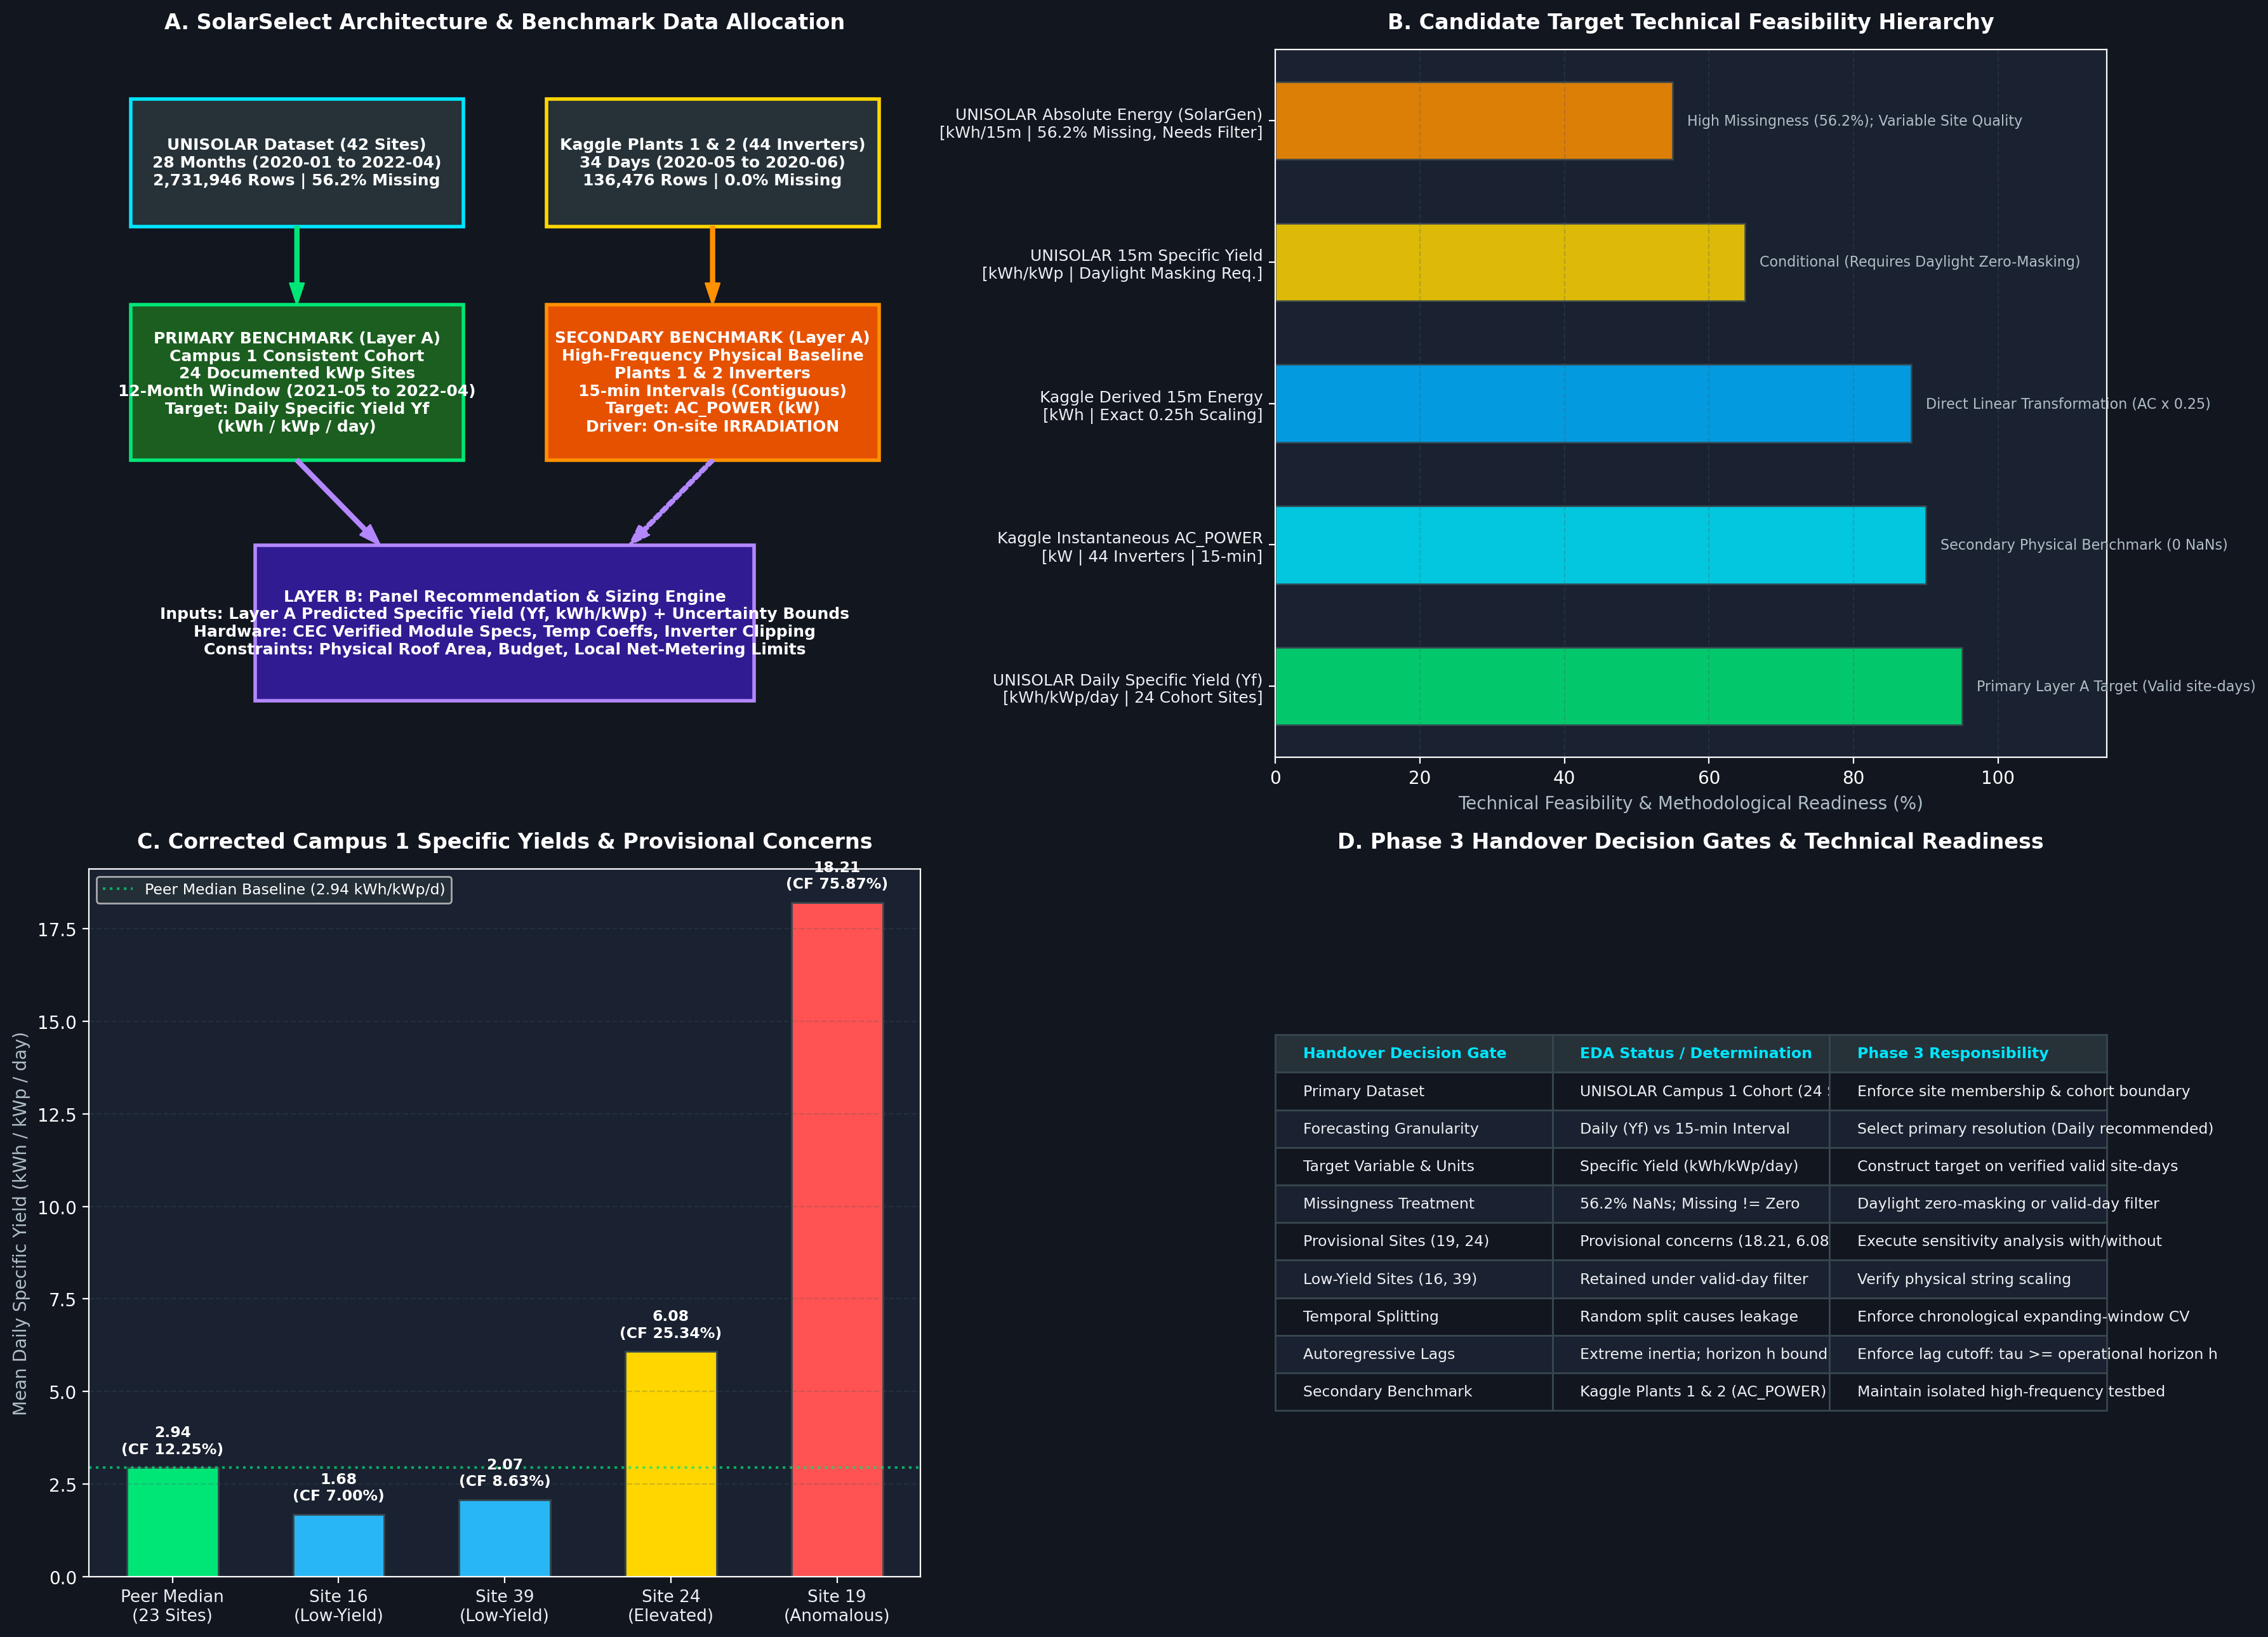

In [4]:
# Display Publication-Grade Phase 2 Consolidation & Handover Figure
summary_fig_path = "figures/phase2_consolidated_dataset_selection_and_handover.png"
if os.path.exists(summary_fig_path):
    display(Image(filename=summary_fig_path))
else:
    print(f"Figure not found at {summary_fig_path}")


---
## 4. Final Dataset Selection and Strategic Roles

### A. UNISOLAR Dataset: Primary Candidate for Layer A
The **UNISOLAR Campus 1 Consistent Cohort (24 Documented-$\text{kW}_p$ Sites, May 2021 – April 2022)** is selected as the **Primary Benchmark Dataset for Layer A Specific Yield Forecasting**.

**Methodological Rationale:**
1. **Capacity Normalization Support:** It contains documented, engineering-verified DC peak capacity ratings (`kWp`) across 24 contiguous rooftop installations, enabling defensible calculation of specific energy yield ($Y_f = \text{kWh}/\text{kW}_p/\text{day}$).
2. **Complete Seasonal Annual Cycle:** The 12-month fixed-cohort window captures an entire annual cycle of Southern-Hemisphere seasonal variability (summer solstice to winter solstice), reflecting true operational weather regimes.
3. **Real-World Commercial Relevance:** Directly models multi-building, multi-inverter commercial rooftop arrays—the exact target application for SolarSelect Layer B panel recommendations.

**Limitations Phase 3 Must Address:**
- **Zero On-Site Irradiance Telemetry:** Requires reliance on proxy ambient weather variables (`AirTemperature`, `RelativeHumidity`) and deterministic astronomical solar zenith angles.
- **High Missingness ($56.23\%$):** Requires strict enforcement of the valid site-day filter ($\ge 26/28$ core daytime intervals) or daylight-conditioned zero masking; missing readings must never be naively imputed with numerical zero.
- **Provisional Data-Quality Sites:** Sites 19 and 24 exhibit non-physical capacity factors ($75.87\%$ and $25.34\%$), requiring dedicated Phase 3 sensitivity analysis.

*Crucial Boundary:* All 42 sites are **not** equally suitable for training. Fleet-wide absolute energy forecasting is limited by missing capacity metadata on 17 sites and substantial sensor gaps outside the verified cohort.

---

### B. Original Kaggle Solar Datasets: Dedicated High-Frequency Physical Benchmark
The **Kaggle Plant 1 & 2 Datasets** are designated as the **Secondary High-Frequency Physical Baseline for Inverter Power Forecasting**.

**Methodological Rationale:**
1. **Direct Irradiance Ground Truth:** Monitored with on-site `IRRADIATION` pyranometer sensors, providing the only empirical testbed for evaluating direct photo-electric conversion efficiency and thermal derating ($dP/dT$).
2. **High Temporal Granularity & Zero Missingness:** 15-minute contiguous intervals with $0.0\%$ null values provide an ideal environment for testing short-horizon nowcasting ($h \le 2\text{h}$) and autoregressive lag persistence.

**Why Kaggle Cannot Support Layer A Core Modeling:**
- **Zero Documented Installed Capacity:** The Kaggle datasets contain zero records of nameplate DC array ratings ($\text{kW}_p$). Reverse-engineering $\text{kW}_p$ from peak output violates physical principles due to inverter clipping ceilings, thermal derating, and DC-to-AC oversizing ratios.
- **Short Temporal Span:** 34 calendar days cannot capture multi-seasonal operational cycles or winter generation dynamics.

---

### C. Cross-Dataset Incompatibility Proof
Joint tabular pooling of Kaggle and UNISOLAR into a single training dataset is **scientifically invalid** and prohibited:
- **Target Semantic Mismatch:** Kaggle measures instantaneous inverter power rate (kW), while UNISOLAR measures integrated interval energy (kWh).
- **Severe Covariate Shift:** Kaggle models are driven by direct on-site `IRRADIATION` ($r = 0.985$); UNISOLAR models are driven by ambient proxy weather ($r = 0.194$). A pooled model would experience severe missing-feature distortion.
- **Climatological Divide:** Tropical semi-arid monsoon conditions (India) vs. temperate Southern-Hemisphere maritime conditions (Australia).
- **Conclusion:** Both datasets must remain strictly partitioned into distinct modeling tracks.


---
## 5. Consolidated Feature and Target Recommendations

### A. Feature Classification Taxonomy
Features across both datasets are formally partitioned into four operational classes:
1. **Recommended Candidate Features:** Physically grounded, available at inference time via standard numerical weather predictions (NWP) or deterministic ephemeris calculations.
2. **Conditional or Cautionary Features:** Features requiring imputation, active availability masks, or specific forecast horizon restrictions.
3. **Excluded Features:** Variables that cause direct target leakage, severe multicollinearity, or sensor channel distortions.
4. **Static Metadata and Identifiers:** Spatial, hardware, and grouping attributes reserved for entity clustering, fixed effects, and Layer B hardware matching.


In [5]:
# Feature Recommendation Classification Table
feature_rec_data = [
    # Kaggle
    {"Dataset": "Kaggle", "Feature": "IRRADIATION", "Classification": "Recommended Candidate", "Role": "Primary Physical Predictive", "Rationale / Limitation": "Overwhelming direct photo-electric driver (r = 0.985). Available via NWP/GHI forecasts at prediction time."},
    {"Dataset": "Kaggle", "Feature": "AMBIENT_TEMPERATURE", "Classification": "Recommended Candidate", "Role": "Secondary Predictive", "Rationale / Limitation": "Co-determines module operating temperature; available via standard forecasts."},
    {"Dataset": "Kaggle", "Feature": "MODULE_TEMPERATURE", "Classification": "Conditional / Cautionary", "Role": "Diagnostic / State Feature", "Rationale / Limitation": "Endogenous physical state; not known at prediction time without coupled thermal modeling. Exclude from operational inputs."},
    {"Dataset": "Kaggle", "Feature": "DC_POWER", "Classification": "Excluded", "Role": "Sensor Artifact", "Rationale / Limitation": "Intermediate conversion state; Plant 1 exhibits 10.0x decimal sensor channel scaling discrepancy."},
    {"Dataset": "Kaggle", "Feature": "DAILY_YIELD / TOTAL_YIELD", "Classification": "Excluded (Leakage)", "Role": "Target Leakage", "Rationale / Limitation": "Running/lifetime cumulative counters allow trivial mathematical inversion of target. Permanently drop."},
    {"Dataset": "Kaggle", "Feature": "DATE_TIME (Cyclical / Lags)", "Classification": "Recommended Candidate", "Role": "Temporal Engineering", "Rationale / Limitation": "Generates cyclical sin/cos hour and autoregressive lags (subject to lag constraint: tau >= forecast horizon h)."},
    {"Dataset": "Kaggle", "Feature": "SOURCE_KEY / PLANT_ID", "Classification": "Static Identifier", "Role": "Entity Clustering", "Rationale / Limitation": "Hierarchical keys for inverter-level fixed effects or spatial clustering."},
    # UNISOLAR
    {"Dataset": "UNISOLAR", "Feature": "AirTemperature", "Classification": "Recommended Candidate", "Role": "Primary Thermal Predictive", "Rationale / Limitation": "Primary weather proxy for seasonal insolation; 3.2% missingness handled via regional campus interpolation."},
    {"Dataset": "UNISOLAR", "Feature": "RelativeHumidity", "Classification": "Recommended Candidate", "Role": "Atmospheric Predictive", "Rationale / Limitation": "Inversely associated with solar insolation (r = -0.228); stable telemetry (3.2% missing)."},
    {"Dataset": "UNISOLAR", "Feature": "WindSpeed", "Classification": "Conditional / Cautionary", "Role": "Thermal Convection", "Rationale / Limitation": "High missingness (43.8%; Campus 2 and 3 missing); requires campus median imputation or exclusion in parsimonious models."},
    {"Dataset": "UNISOLAR", "Feature": "Apparent / DewPoint Temp", "Classification": "Excluded (Collinear)", "Role": "Collinear Redundancy", "Rationale / Limitation": "Severe collinearity with AirTemperature (r = 0.964); causes severe variance inflation in linear/regularized models."},
    {"Dataset": "UNISOLAR", "Feature": "Timestamp (Cyclical / Month)", "Classification": "Recommended Candidate", "Role": "Temporal / Solar Ephemeris", "Rationale / Limitation": "Source for diurnal sin/cos hour, calendar month, and deterministic solar zenith angle calculations."},
    {"Dataset": "UNISOLAR", "Feature": "SiteKey / CampusKey", "Classification": "Static Identifier", "Role": "Hierarchical Grouping", "Rationale / Limitation": "Grouping entities for spatial pooling, multi-task architectures, or campus-level fixed effects."},
    {"Dataset": "UNISOLAR", "Feature": "kWp (Nameplate Capacity)", "Classification": "Static Metadata", "Role": "Target Normalizer", "Rationale / Limitation": "Mandatory normalizer for specific yield (Yf = kWh/kWp). Documented only on Campus 1 (25 sites; 24 in cohort)."},
    {"Dataset": "UNISOLAR", "Feature": "Panel / Inverter Hardware", "Classification": "Static Metadata", "Role": "Layer B Integration", "Rationale / Limitation": "Module count and hardware strings reserved for Layer B datasheet matching and validation."}
]

df_feature_rec = pd.DataFrame(feature_rec_data)
print("=== CONSOLIDATED FEATURE RECOMMENDATION TAXONOMY ===")
display(df_feature_rec[["Dataset", "Feature", "Classification", "Role", "Rationale / Limitation"]])


=== CONSOLIDATED FEATURE RECOMMENDATION TAXONOMY ===


,Dataset,Feature,Classification,Role,Rationale / Limitation
0,Kaggle,IRRADIATION,Recommended Candidate,Primary Physical Predictive,Overwhelming direct photo-electric driver (r = 0.985). Available via NWP/GHI forecasts at prediction time.
1,Kaggle,AMBIENT_TEMPERATURE,Recommended Candidate,Secondary Predictive,Co-determines module operating temperature; available via standard forecasts.
2,Kaggle,MODULE_TEMPERATURE,Conditional / Cautionary,Diagnostic / State Feature,Endogenous physical state; not known at prediction time without coupled thermal modeling. Exclude from operational inputs.
3,Kaggle,DC_POWER,Excluded,Sensor Artifact,Intermediate conversion state; Plant 1 exhibits 10.0x decimal sensor channel scaling discrepancy.
4,Kaggle,DAILY_YIELD / TOTAL_YIELD,Excluded (Leakage),Target Leakage,Running/lifetime cumulative counters allow trivial mathematical inversion of target. Permanently drop.
5,Kaggle,DATE_TIME (Cyclical / Lags),Recommended Candidate,Temporal Engineering,Generates cyclical sin/cos hour and autoregressive lags (subject to lag constraint: tau >= forecast horizon h).
6,Kaggle,SOURCE_KEY / PLANT_ID,Static Identifier,Entity Clustering,Hierarchical keys for inverter-level fixed effects or spatial clustering.
7,UNISOLAR,AirTemperature,Recommended Candidate,Primary Thermal Predictive,Primary weather proxy for seasonal insolation; 3.2% missingness handled via regional campus interpolation.
8,UNISOLAR,RelativeHumidity,Recommended Candidate,Atmospheric Predictive,Inversely associated with solar insolation (r = -0.228); stable telemetry (3.2% missing).
9,UNISOLAR,WindSpeed,Conditional / Cautionary,Thermal Convection,High missingness (43.8%; Campus 2 and 3 missing); requires campus median imputation or exclusion in parsimonious models.


### B. Target Variable Feasibility Comparison
A technical audit was performed across five potential target formulations to evaluate dimensional consistency, capacity normalization, missingness handling, and alignment with SolarSelect's dual-layer architecture.


In [6]:
# Target Variable Comparison Table
target_comp_data = [
    {
        "Candidate Target": "1. Daily Specific Yield (Yf)",
        "Dataset Source": "UNISOLAR (Campus 1 Cohort)",
        "Target Unit": "kWh / kWp / day",
        "Granularity": "Daily (Valid site-days)",
        "Capacity Normalized?": "Yes (Documented kWp)",
        "Missingness Challenge": "Zero on valid site-days (>= 26/28 core intervals)",
        "Technical Feasibility": "High (Recommended Primary Target for Layer A)",
        "Layer A / Layer B Alignment": "Directly matches commercial solar sizing standards; feeds predicted kWh/kWp directly into Layer B panel sizing."
    },
    {
        "Candidate Target": "2. Instantaneous AC Power",
        "Dataset Source": "Kaggle Plants 1 & 2",
        "Target Unit": "kW (Instantaneous Rate)",
        "Granularity": "15-minute",
        "Capacity Normalized?": "No (0 kWp metadata)",
        "Missingness Challenge": "0.0% nulls (Contiguous)",
        "Technical Feasibility": "High (Recommended Secondary Physical Benchmark)",
        "Layer A / Layer B Alignment": "Ideal for nowcasting and photo-conversion modeling; cannot directly size panels in Layer B without capacity ratings."
    },
    {
        "Candidate Target": "3. Derived 15-min Energy",
        "Dataset Source": "Kaggle Plants 1 & 2",
        "Target Unit": "kWh / 15-min",
        "Granularity": "15-minute",
        "Capacity Normalized?": "No (0 kWp metadata)",
        "Missingness Challenge": "0.0% nulls",
        "Technical Feasibility": "High (Linear conversion: AC_POWER x 0.25h)",
        "Layer A / Layer B Alignment": "Exact linear scaling of AC power; shares identical modeling properties and limitations as Target 2."
    },
    {
        "Candidate Target": "4. 15-min Specific Yield (Yf,15m)",
        "Dataset Source": "UNISOLAR (Campus 1 Cohort)",
        "Target Unit": "kWh / kWp / 15-min",
        "Granularity": "15-minute",
        "Capacity Normalized?": "Yes (Documented kWp)",
        "Missingness Challenge": "56.23% nulls; requires daylight zero-masking",
        "Technical Feasibility": "Conditional (Feasible with strict solar zenith masking)",
        "Layer A / Layer B Alignment": "Provides sub-hourly generation profiles; requires Phase 3 to solve nighttime zero-inflation and interval noise."
    },
    {
        "Candidate Target": "5. Absolute Interval Energy (SolarGen)",
        "Dataset Source": "UNISOLAR (Fleet-Wide 42 Sites)",
        "Target Unit": "kWh / 15-min",
        "Granularity": "15-minute",
        "Capacity Normalized?": "No (17/42 sites missing kWp)",
        "Missingness Challenge": "56.23% nulls (1,536,301 missing rows)",
        "Technical Feasibility": "Moderate (Requires extensive observation filtering)",
        "Layer A / Layer B Alignment": "Absolute energy depends heavily on unknown building array scale; cannot transfer predictions to new user sites in Layer B."
    }
]

df_target_comp = pd.DataFrame(target_comp_data)
print("=== TARGET VARIABLE FEASIBILITY & STRATEGIC COMPARISON ===")
display(df_target_comp[["Candidate Target", "Target Unit", "Granularity", "Capacity Normalized?", "Technical Feasibility", "Layer A / Layer B Alignment"]])


=== TARGET VARIABLE FEASIBILITY & STRATEGIC COMPARISON ===


,Candidate Target,Target Unit,Granularity,Capacity Normalized?,Technical Feasibility,Layer A / Layer B Alignment
0,1. Daily Specific Yield (Yf),kWh / kWp / day,Daily (Valid site-days),Yes (Documented kWp),High (Recommended Primary Target for Layer A),Directly matches commercial solar sizing standards; feeds predicted kWh/kWp directly into Layer B panel sizing.
1,2. Instantaneous AC Power,kW (Instantaneous Rate),15-minute,No (0 kWp metadata),High (Recommended Secondary Physical Benchmark),Ideal for nowcasting and photo-conversion modeling; cannot directly size panels in Layer B without capacity ratings.
2,3. Derived 15-min Energy,kWh / 15-min,15-minute,No (0 kWp metadata),High (Linear conversion: AC_POWER x 0.25h),Exact linear scaling of AC power; shares identical modeling properties and limitations as Target 2.
3,"4. 15-min Specific Yield (Yf,15m)",kWh / kWp / 15-min,15-minute,Yes (Documented kWp),Conditional (Feasible with strict solar zenith masking),Provides sub-hourly generation profiles; requires Phase 3 to solve nighttime zero-inflation and interval noise.
4,5. Absolute Interval Energy (SolarGen),kWh / 15-min,15-minute,No (17/42 sites missing kWp),Moderate (Requires extensive observation filtering),Absolute energy depends heavily on unknown building array scale; cannot transfer predictions to new user sites in Layer B.


---
## 6. Consolidated Limitations and Risk Register

To ensure methodological traceability and prevent modeling failures in Phase 3 and production, all empirical anomalies, data constraints, and physical limitations identified during EDA are formalized in the **SolarSelect 14-Item Risk Register**.


In [7]:
# Consolidated 14-Item Limitations & Risk Register
risk_register_data = [
    {
        "Risk ID": "RISK-01",
        "Description": "Generation Missingness & Nighttime Ambiguity",
        "Affected Dataset": "UNISOLAR Generation",
        "Severity": "High",
        "EDA Evidence": "56.23% of rows (1,536,301 nulls) are NaN; 0 exact zeros exist in dataset; per-site minimum is 0.100-0.125 kWh.",
        "Phase 3 Implication": "Conflates genuine night/sub-threshold states with communication outages. Naive zero-imputation distorts empirical capacity factors.",
        "Recommended Handling": "Enforce valid site-day filter (>= 26/28 core daytime intervals) for daily modeling, or apply solar zenith angle zero-masking for interval modeling."
    },
    {
        "Risk ID": "RISK-02",
        "Description": "Missing Capacity Metadata (17 Sites)",
        "Affected Dataset": "UNISOLAR Site Details",
        "Severity": "High",
        "EDA Evidence": "40.48% of sites (Campuses 2-5 and Campus 1 Sites 28-29) lack kWp nameplate ratings in Solar_Site_Details.csv.",
        "Phase 3 Implication": "Cannot compute capacity-normalized specific yield (Yf) without reverse-engineering capacity, which violates project rules.",
        "Recommended Handling": "Strictly bound Layer A capacity-normalized training to the 24 documented Campus 1 cohort sites."
    },
    {
        "Risk ID": "RISK-03",
        "Description": "Regional Weather Telemetry Missingness",
        "Affected Dataset": "UNISOLAR Weather",
        "Severity": "Medium",
        "EDA Evidence": "28.81% nulls in temperature; 43.81% nulls in wind speed; Campus 2 has no weather; Campus 3 has no wind telemetry.",
        "Phase 3 Implication": "Models relying on un-imputed wind speed or Campus 2 weather will fail during batch feature transformation.",
        "Recommended Handling": "Exclude WindSpeed from primary feature set or impute via campus medians; map Campus 1 weather to co-located sites."
    },
    {
        "Risk ID": "RISK-04",
        "Description": "Timestamp Alignment & Join Gaps",
        "Affected Dataset": "Kaggle & UNISOLAR",
        "Severity": "Medium",
        "EDA Evidence": "Kaggle uses divergent string timestamp formats (%d-%m-%Y vs %Y-%m-%d). Campus 1 has 364 missing-row gaps (median 27.25h).",
        "Phase 3 Implication": "Asynchronous inner joins drop generation timestamps; naive resampling across gaps creates artificial zero sequences.",
        "Recommended Handling": "Standardize timestamps to UTC/ISO format prior to joining; resample only within verified contiguous calendar days."
    },
    {
        "Risk ID": "RISK-05",
        "Description": "Kaggle Brief Observation Duration",
        "Affected Dataset": "Kaggle Plants 1 & 2",
        "Severity": "High",
        "EDA Evidence": "Spans exactly 34 calendar days (May 15 to June 17, 2020) during Indian pre-monsoon/monsoon transition.",
        "Phase 3 Implication": "Zero winter, autumn, or spring operational coverage; models cannot learn seasonal solar declination cycles.",
        "Recommended Handling": "Restrict Kaggle strictly to short-horizon nowcasting and physical photo-conversion benchmarks; do not extrapolate annually."
    },
    {
        "Risk ID": "RISK-06",
        "Description": "Plant 2 Inverter Availability Dropouts",
        "Affected Dataset": "Kaggle Plant 2 Gen",
        "Severity": "Medium",
        "EDA Evidence": "27.7% of timestamps (904 intervals) have fewer than the full 22 active inverters reporting power.",
        "Phase 3 Implication": "Summing plant power across missing inverters creates artificial generation drops unrelated to solar irradiance.",
        "Recommended Handling": "Train models at the individual inverter level or construct active-inverter availability masks when predicting plant-aggregate power."
    },
    {
        "Risk ID": "RISK-07",
        "Description": "Plant 2 Midday Inverter Counter Resets",
        "Affected Dataset": "Kaggle Plant 2 Gen",
        "Severity": "Medium",
        "EDA Evidence": "Inverter rrq4fwMUR8DrLLm resets DAILY_YIELD from ~8000 to 0 midday; TOTAL_YIELD resets by hundreds of MWh.",
        "Phase 3 Implication": "Any model trained on raw cumulative counters experiences severe label distortion and catastrophic inference error.",
        "Recommended Handling": "Permanently drop DAILY_YIELD and TOTAL_YIELD from all predictive feature sets during data preparation."
    },
    {
        "Risk ID": "RISK-08",
        "Description": "Site 19 & Site 24 Specific-Yield Anomalies",
        "Affected Dataset": "UNISOLAR Campus 1",
        "Severity": "Medium",
        "EDA Evidence": "Site 19 window Yf = 18.21 kWh/kWp/d (CF 75.87%); Site 24 window Yf = 6.08 kWh/kWp/d (CF 25.34%) vs peer median 2.94.",
        "Phase 3 Implication": "Substantially elevated specific yields distort capacity-normalized loss functions if included without adjustment.",
        "Recommended Handling": "Conduct sensitivity analysis in Phase 3: train models with and without Sites 19 and 24 to quantify impact on loss and stability."
    },
    {
        "Risk ID": "RISK-09",
        "Description": "Site 16 & Site 39 Low Observed Yields",
        "Affected Dataset": "UNISOLAR Campus 1",
        "Severity": "Low",
        "EDA Evidence": "Window Yf = 1.68 and 2.07 kWh/kWp/d (0.57x and 0.70x peer median); entry dates (2020-12-09 and 2020-08-21) strictly first seen.",
        "Phase 3 Implication": "Reflects low-performing physical installations (shading/orientation/strings) rather than fatal telemetry errors.",
        "Recommended Handling": "Retain in training set under valid site-day filter; evaluate whether site fixed effects capture lower physical baselines."
    },
    {
        "Risk ID": "RISK-10",
        "Description": "Absence of Direct Irradiance in UNISOLAR",
        "Affected Dataset": "UNISOLAR Fleet",
        "Severity": "High",
        "EDA Evidence": "UNISOLAR contains zero on-site pyranometer sensors; ambient temperature correlates weakly with generation (r = 0.194).",
        "Phase 3 Implication": "Models cannot learn deterministic photon-to-power transfer functions; requires reliance on proxy weather and time features.",
        "Recommended Handling": "Engineer astronomical solar zenith and azimuth angles; design pipeline to ingest external NWP/GHI forecasts for production inference."
    },
    {
        "Risk ID": "RISK-11",
        "Description": "Cross-Dataset Tabular Incompatibility",
        "Affected Dataset": "Kaggle & UNISOLAR",
        "Severity": "High",
        "EDA Evidence": "Target mismatch (kW vs kWh), covariate shift (irradiance present vs absent), disparate climates and observation durations.",
        "Phase 3 Implication": "Pooling datasets into a joint tabular matrix corrupts physical loss gradients and invalidates cross-validation.",
        "Recommended Handling": "Enforce strict architectural separation: UNISOLAR for Layer A multi-seasonal Yf modeling, Kaggle for physical benchmarking."
    },
    {
        "Risk ID": "RISK-12",
        "Description": "Temporal Information Leakage",
        "Affected Dataset": "Time-Series Features",
        "Severity": "High",
        "EDA Evidence": "Extreme autoregressive persistence (Lag 1 r > 0.92); future weather and target values leak under random splitting.",
        "Phase 3 Implication": "Random k-fold cross-validation inflates validation R2 to near-perfection while model fails completely on unseen future dates.",
        "Recommended Handling": "Mandate strict chronological train/validation/test splits or purged expanding-window time-series CV with lag embargoes."
    },
    {
        "Risk ID": "RISK-13",
        "Description": "Weather Feature Multicollinearity",
        "Affected Dataset": "UNISOLAR Weather",
        "Severity": "Low",
        "EDA Evidence": "AirTemperature and ApparentTemperature correlate at r = 0.9641; RelativeHumidity correlates at r = -0.7268.",
        "Phase 3 Implication": "Causes severe variance inflation, unstable regression coefficients, and redundant computational overhead in gradient boosters.",
        "Recommended Handling": "Select AirTemperature as primary thermal feature; permanently exclude ApparentTemperature and DewPointTemperature."
    },
    {
        "Risk ID": "RISK-14",
        "Description": "Uncertainty in Long-Term Climatological Norms",
        "Affected Dataset": "UNISOLAR 28-Month Span",
        "Severity": "Medium",
        "EDA Evidence": "Fixed cohort covers exactly 1 complete annual cycle (12 mos); broader dataset spans 28 mos with variable commissioning.",
        "Phase 3 Implication": "A single annual cycle does not represent multi-decadal climatology; inter-annual weather shifts introduce baseline drift.",
        "Recommended Handling": "Incorporate calibrated prediction intervals (conformal prediction or quantile regression) in Layer A to express uncertainty in Layer B."
    }
]

df_risks = pd.DataFrame(risk_register_data)
print("=== CONSOLIDATED 14-ITEM LIMITATIONS & RISK REGISTER ===")
display(df_risks[["Risk ID", "Description", "Severity", "Affected Dataset", "Recommended Handling"]])


=== CONSOLIDATED 14-ITEM LIMITATIONS & RISK REGISTER ===


,Risk ID,Description,Severity,Affected Dataset,Recommended Handling
0,RISK-01,Generation Missingness & Nighttime Ambiguity,High,UNISOLAR Generation,"Enforce valid site-day filter (>= 26/28 core daytime intervals) for daily modeling, or apply solar zenith angle zero-masking for interval modeling."
1,RISK-02,Missing Capacity Metadata (17 Sites),High,UNISOLAR Site Details,Strictly bound Layer A capacity-normalized training to the 24 documented Campus 1 cohort sites.
2,RISK-03,Regional Weather Telemetry Missingness,Medium,UNISOLAR Weather,Exclude WindSpeed from primary feature set or impute via campus medians; map Campus 1 weather to co-located sites.
3,RISK-04,Timestamp Alignment & Join Gaps,Medium,Kaggle & UNISOLAR,Standardize timestamps to UTC/ISO format prior to joining; resample only within verified contiguous calendar days.
4,RISK-05,Kaggle Brief Observation Duration,High,Kaggle Plants 1 & 2,Restrict Kaggle strictly to short-horizon nowcasting and physical photo-conversion benchmarks; do not extrapolate annually.
5,RISK-06,Plant 2 Inverter Availability Dropouts,Medium,Kaggle Plant 2 Gen,Train models at the individual inverter level or construct active-inverter availability masks when predicting plant-aggregate power.
6,RISK-07,Plant 2 Midday Inverter Counter Resets,Medium,Kaggle Plant 2 Gen,Permanently drop DAILY_YIELD and TOTAL_YIELD from all predictive feature sets during data preparation.
7,RISK-08,Site 19 & Site 24 Specific-Yield Anomalies,Medium,UNISOLAR Campus 1,Conduct sensitivity analysis in Phase 3: train models with and without Sites 19 and 24 to quantify impact on loss and stability.
8,RISK-09,Site 16 & Site 39 Low Observed Yields,Low,UNISOLAR Campus 1,Retain in training set under valid site-day filter; evaluate whether site fixed effects capture lower physical baselines.
9,RISK-10,Absence of Direct Irradiance in UNISOLAR,High,UNISOLAR Fleet,Engineer astronomical solar zenith and azimuth angles; design pipeline to ingest external NWP/GHI forecasts for production inference.


---
## 7. Phase 3 Handover: Target Definition and Data Preparation

Phase 3 is tasked with **Target Definition, Data Cleaning, and Feature Engineering Pipeline Construction**.

To ensure a seamless transition and prevent reopening resolved analytical questions, the handover is structured into **14 Formal Decision Gates**, explicitly distinguishing decisions already conclusively determined by EDA from open implementation decisions reserved for Phase 3.


In [8]:
# Phase 3 Handover 14-Item Technical Decision Matrix
handover_data = [
    {
        "Gate": "1. Layer A Primary Dataset",
        "EDA Determination (Closed)": "UNISOLAR Campus 1 Consistent Cohort (24 documented-kWp sites, May 2021 - Apr 2022).",
        "Phase 3 Implementation Task": "Enforce cohort filtering; isolate the 24 documented installations from unrecorded campuses."
    },
    {
        "Gate": "2. Forecasting Granularity",
        "EDA Determination (Closed)": "Daily specific yield (kWh/kWp/day) provides cleanest physical signal and matches Layer B; 15-min interval is conditional.",
        "Phase 3 Implementation Task": "Finalize primary modeling resolution: select Daily Yf for core baseline; evaluate 15-min as secondary experiment."
    },
    {
        "Gate": "3. Exact Target Definition",
        "EDA Determination (Closed)": "Yf = Sum(E_15m) / kWp on verified valid site-days (>= 26/28 core daytime intervals).",
        "Phase 3 Implementation Task": "Implement vectorized target calculation script enforcing valid-day aggregation logic."
    },
    {
        "Gate": "4. Operational Forecast Horizon",
        "EDA Determination (Closed)": "Autoregressive inertia cuts off after lag 2 (30m); nowcasting (h <= 2h) vs Day-Ahead (h = 24h) require different feature sets.",
        "Phase 3 Implementation Task": "Define operational horizon h (e.g. Day-Ahead h = 24h) to fix the lag availability boundary (tau >= h)."
    },
    {
        "Gate": "5. Feature Availability at Prediction Time",
        "EDA Determination (Closed)": "Endogenous states (MODULE_TEMPERATURE, DC_POWER) and counters (DAILY_YIELD) unavailable/leakage.",
        "Phase 3 Implementation Task": "Construct feature store containing only exogenous weather predictions and deterministic ephemeris features."
    },
    {
        "Gate": "6. Weather Missingness Treatment",
        "EDA Determination (Closed)": "AirTemperature (3.2% missing) is stable; WindSpeed (43.8% missing) is unreliable; ApparentTemperature redundant.",
        "Phase 3 Implementation Task": "Drop Apparent/DewPoint; apply forward-fill or campus median imputation for AirTemperature; test model with/without wind."
    },
    {
        "Gate": "7. Generation Telemetry Filtering",
        "EDA Determination (Closed)": "56.23% NaNs represent sub-threshold (<0.1 kWh) and dropouts. Naive zero-imputation is prohibited.",
        "Phase 3 Implementation Task": "Implement valid site-day filter (96 rows + >= 26 core non-null intervals); drop invalid site-days from training."
    },
    {
        "Gate": "8. Treatment of Sites 19 & 24",
        "EDA Determination (Closed)": "Corrected specific yields (18.21 and 6.08 kWh/kWp/d) are provisional concerns; hypotheses retained without exclusion.",
        "Phase 3 Implementation Task": "Execute formal sensitivity analysis: benchmark models trained with vs. without Sites 19 and 24."
    },
    {
        "Gate": "9. Treatment of Sites 16 & 39",
        "EDA Determination (Closed)": "Low-yield operational installations (1.68 and 2.07 kWh/kWp/d); first-seen dates strictly entry points.",
        "Phase 3 Implementation Task": "Retain in training set under valid site-day filter; evaluate whether site fixed effects adequately account for baselines."
    },
    {
        "Gate": "10. Temporal Splitting Strategy",
        "EDA Determination (Closed)": "Random temporal shuffling causes catastrophic target/weather leakage.",
        "Phase 3 Implementation Task": "Implement strict chronological train/validation/test splits (e.g., 8 mos train, 2 mos val, 2 mos test) or rolling-origin CV."
    },
    {
        "Gate": "11. Lag & Rolling Feature Rules",
        "EDA Determination (Closed)": "Autoregressive generation lags must be restricted to tau >= h to prevent future lookahead.",
        "Phase 3 Implementation Task": "Construct lag feature transformation pipeline enforcing horizon-conditioned embargoes."
    },
    {
        "Gate": "12. Leakage Prevention Protocol",
        "EDA Determination (Closed)": "Permanent removal of DAILY_YIELD and TOTAL_YIELD counters.",
        "Phase 3 Implementation Task": "Incorporate automated assertion checks in data pipeline to guarantee cumulative counters never enter feature matrix."
    },
    {
        "Gate": "13. Role of Kaggle Benchmark",
        "EDA Determination (Closed)": "Dedicated high-frequency physical power testbed; completely isolated from UNISOLAR Layer A training.",
        "Phase 3 Implementation Task": "Maintain separate preprocessing pipeline for Kaggle Plants 1 & 2 short-horizon nowcasting benchmark."
    },
    {
        "Gate": "14. Reproducibility & Data Versioning",
        "EDA Determination (Closed)": "Raw datasets in data/raw/ are immutable read-only sources of truth.",
        "Phase 3 Implementation Task": "Establish DVC tracking for raw data; version processed feature matrices in data/processed/."
    }
]

df_handover = pd.DataFrame(handover_data)
print("=== PHASE 3 TECHNICAL HANDOVER: 14-ITEM DECISION MATRIX ===")
display(df_handover[["Gate", "EDA Determination (Closed)", "Phase 3 Implementation Task"]])


=== PHASE 3 TECHNICAL HANDOVER: 14-ITEM DECISION MATRIX ===


,Gate,EDA Determination (Closed),Phase 3 Implementation Task
0,1. Layer A Primary Dataset,"UNISOLAR Campus 1 Consistent Cohort (24 documented-kWp sites, May 2021 - Apr 2022).",Enforce cohort filtering; isolate the 24 documented installations from unrecorded campuses.
1,2. Forecasting Granularity,Daily specific yield (kWh/kWp/day) provides cleanest physical signal and matches Layer B; 15-min interval is conditional.,Finalize primary modeling resolution: select Daily Yf for core baseline; evaluate 15-min as secondary experiment.
2,3. Exact Target Definition,Yf = Sum(E_15m) / kWp on verified valid site-days (>= 26/28 core daytime intervals).,Implement vectorized target calculation script enforcing valid-day aggregation logic.
3,4. Operational Forecast Horizon,Autoregressive inertia cuts off after lag 2 (30m); nowcasting (h <= 2h) vs Day-Ahead (h = 24h) require different feature sets.,Define operational horizon h (e.g. Day-Ahead h = 24h) to fix the lag availability boundary (tau >= h).
4,5. Feature Availability at Prediction Time,"Endogenous states (MODULE_TEMPERATURE, DC_POWER) and counters (DAILY_YIELD) unavailable/leakage.",Construct feature store containing only exogenous weather predictions and deterministic ephemeris features.
5,6. Weather Missingness Treatment,AirTemperature (3.2% missing) is stable; WindSpeed (43.8% missing) is unreliable; ApparentTemperature redundant.,Drop Apparent/DewPoint; apply forward-fill or campus median imputation for AirTemperature; test model with/without wind.
6,7. Generation Telemetry Filtering,56.23% NaNs represent sub-threshold (<0.1 kWh) and dropouts. Naive zero-imputation is prohibited.,Implement valid site-day filter (96 rows + >= 26 core non-null intervals); drop invalid site-days from training.
7,8. Treatment of Sites 19 & 24,Corrected specific yields (18.21 and 6.08 kWh/kWp/d) are provisional concerns; hypotheses retained without exclusion.,Execute formal sensitivity analysis: benchmark models trained with vs. without Sites 19 and 24.
8,9. Treatment of Sites 16 & 39,Low-yield operational installations (1.68 and 2.07 kWh/kWp/d); first-seen dates strictly entry points.,Retain in training set under valid site-day filter; evaluate whether site fixed effects adequately account for baselines.
9,10. Temporal Splitting Strategy,Random temporal shuffling causes catastrophic target/weather leakage.,"Implement strict chronological train/validation/test splits (e.g., 8 mos train, 2 mos val, 2 mos test) or rolling-origin CV."


---
## 8. Phase 2 Formal Closure Summary

### Final Analytical Verdict:
Phase 2 (Exploratory Data Analysis) has successfully concluded all empirical investigations across the eight SolarSelect datasets. 

**Summary of Key Achievements:**
1. **Mathematical & Schema Integrity Established:** Reconciled row counts, composite join keys, and multi-tiered missingness patterns across Kaggle ($136,476$ rows) and UNISOLAR ($2,731,946$ rows).
2. **Systemic Hardware Scaling Discovered:** Uncovered the $10.0\times$ decimal sensor scaling discrepancy in Kaggle Plant 1 (`DC_POWER`) and established that UNISOLAR nighttime records ($177$ intervals) reflect discrete meter pulse quantization and logger clock shifts rather than continuous night power.
3. **Capacity-Normalized Specific Yield Corrected:** Replaced inflated formulas with valid site-day energy integration divided by documented $\text{kW}_p$, establishing an empirical peer baseline of **$2.94\text{ kWh}/\text{kW}_p/\text{day}$** (IQR $[2.86, 3.12]$) and identifying provisional data-quality concerns at Sites 19 ($18.21$) and 24 ($6.08$).
4. **Controlled Seasonality Characterized:** Built the consistent 37-site cohort (24 documented-capacity sites) over a **12-month complete annual cycle (May 2021 – April 2022)**, proving that fleet-wide generation varies by **$2.36\times–2.55\times$** between summer and winter. Confirmed weekday/weekend generation differences are statistically non-significant ($p = 0.1055$).
5. **Architectural Roles & Leakage Controls Finalized:** Proved that joint tabular pooling of Kaggle and UNISOLAR is scientifically invalid. Designated the UNISOLAR Campus 1 cohort as the Primary Benchmark for Layer A specific yield forecasting, and Kaggle as a secondary high-frequency physical benchmark. Formulated the 14-item risk register and 14-gate Phase 3 technical handover.

**Phase 2 is formally complete and closed.** All analytical prerequisites for Phase 3 (Target Definition and Data Preparation) are satisfied.
